**IMPORT LIBRARIES**

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

**LOAD DATASET**

In [3]:
# Load the dataset
df = pd.read_csv("Advertising Budget and Sales.csv")

# Display first five rows
df.head()

,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


Checking the dataset shape and column names.

In [4]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null counts
df.info()

Dataset Shape: (200, 5)

Columns:
['Unnamed: 0', 'TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)', 'Sales ($)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               200 non-null    int64  
 1   TV Ad Budget ($)         200 non-null    float64
 2   Radio Ad Budget ($)      200 non-null    float64
 3   Newspaper Ad Budget ($)  200 non-null    float64
 4   Sales ($)                200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


**Missing Values**

In [5]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Unnamed: 0                 0
TV Ad Budget ($)           0
Radio Ad Budget ($)        0
Newspaper Ad Budget ($)    0
Sales ($)                  0
dtype: int64


**Duplicate Rows**

In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**Zero duplicate rows no processing needed**

**Descriptive statistics**

In [8]:
df.describe()

,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


**Processing Dataset column names**

In [10]:
df = df.loc[:, ~df.columns.str.contains("^Unnamed")] # removing unnamed column from df

In [11]:
#renaming column names
df.rename(columns={
    'TV Ad Budget ($)': 'TV_Ad_Budget',
    'Radio Ad Budget ($)': 'Radio_Ad_Budget',
    'Newspaper Ad Budget ($)': 'Newspaper_Ad_Budget',
    'Sales ($)': 'Sales'
}, inplace=True)

/tmp/ipykernel_1190/4022859634.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={


**Check the target distribution**

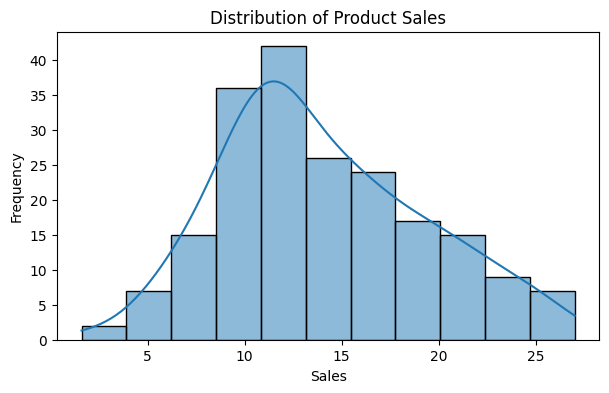

In [12]:
plt.figure(figsize=(7, 4))

sns.histplot(df["Sales"], kde=True)

plt.title("Distribution of Product Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

**Pairplot of all features**

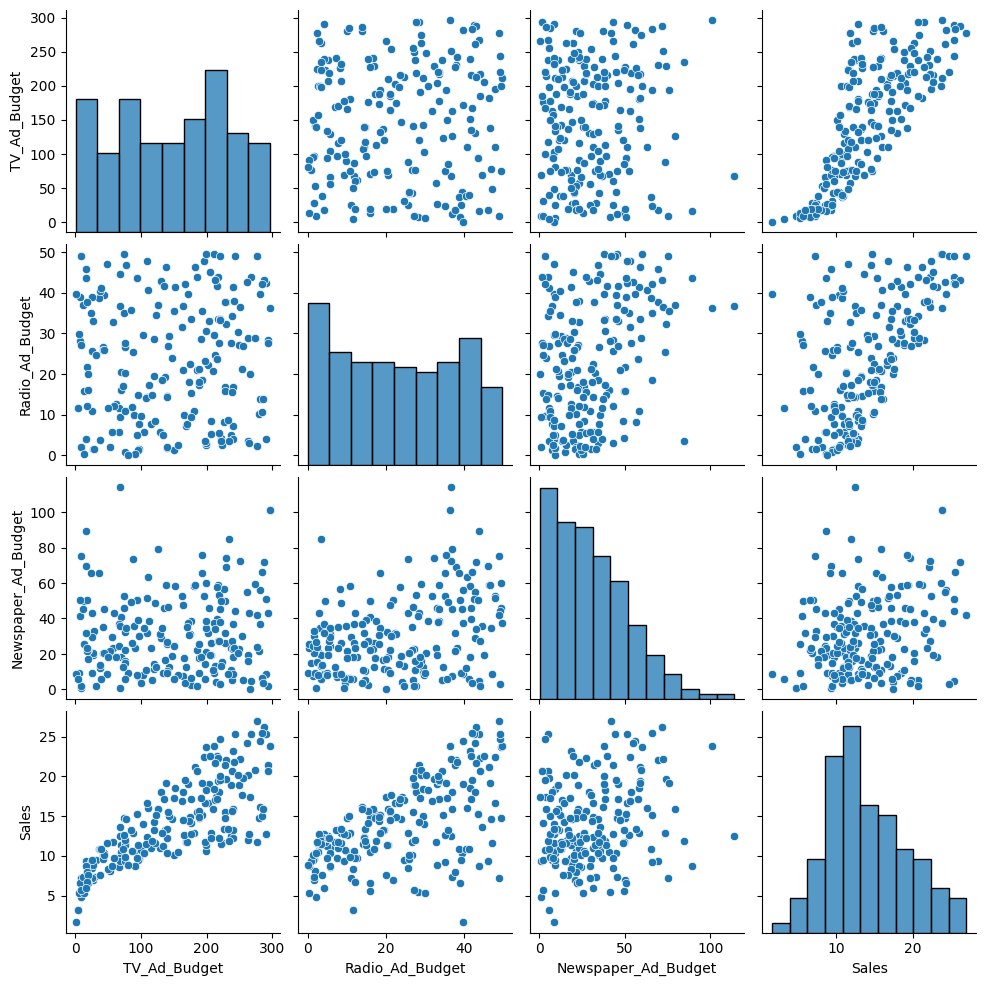

In [13]:
sns.pairplot(df)
plt.show()

**Individual scatterplots**

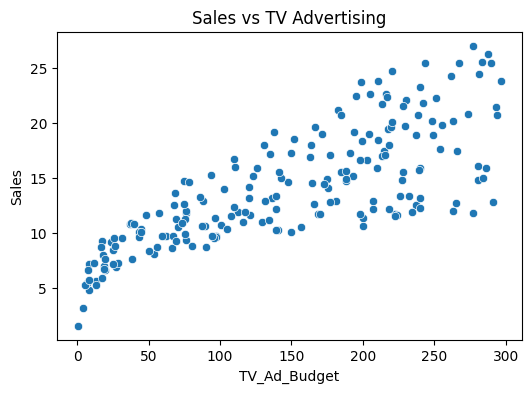

In [15]:
# Sales vs TV advertising
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="TV_Ad_Budget", y="Sales")
plt.title("Sales vs TV Advertising")
plt.show()

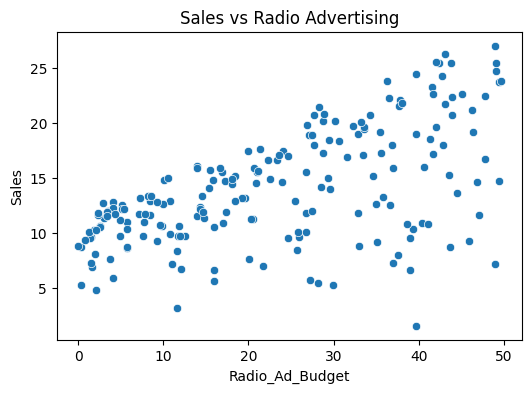

In [17]:
# Sales vs Radio advertising
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Radio_Ad_Budget", y="Sales")
plt.title("Sales vs Radio Advertising")
plt.show()

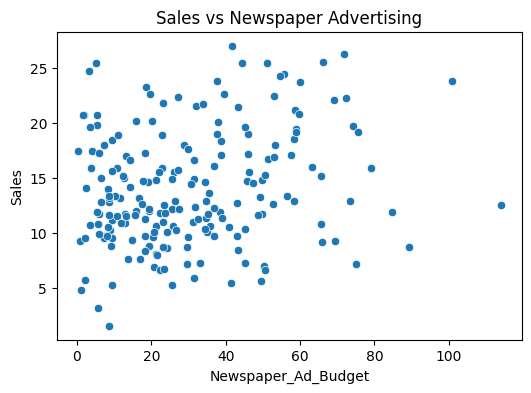

In [18]:
# Sales vs Newspaper advertising
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Newspaper_Ad_Budget", y="Sales")
plt.title("Sales vs Newspaper Advertising")
plt.show()

**Correlation matrix heatmap**

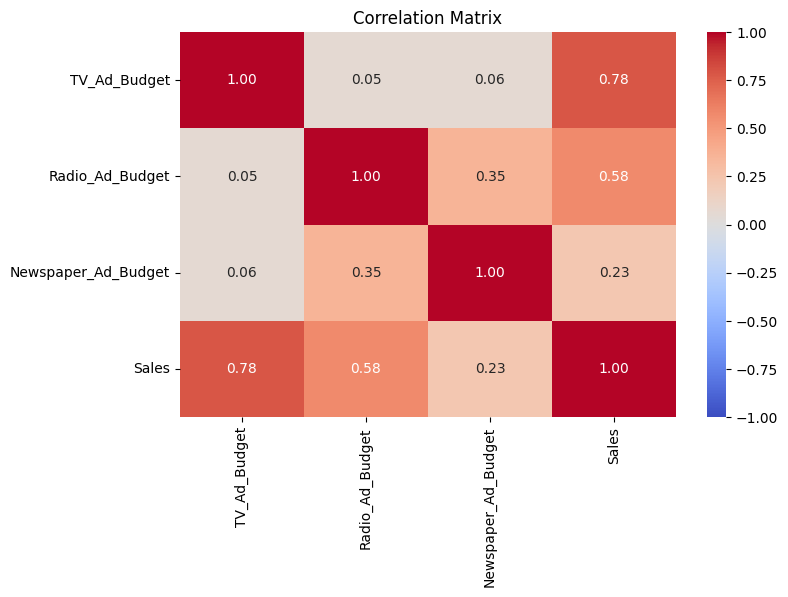

In [19]:
# Calculate correlations between numerical columns
corr_matrix = df.corr(numeric_only=True)

# Plot heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.show()

**Defining features and target**

In [21]:
# Input features
X = df[["TV_Ad_Budget", "Radio_Ad_Budget", "Newspaper_Ad_Budget"]]

# Target variable
y = df["Sales"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (200, 3)
Target shape: (200,)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (160, 3)
X_test: (40, 3)
y_train: (160,)
y_test: (40,)


In [23]:
# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [24]:
print("Intercept:", lr_model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_
})

print(coefficients)

Intercept: 2.979067338122629
               Feature  Coefficient
0         TV_Ad_Budget     0.044730
1      Radio_Ad_Budget     0.189195
2  Newspaper_Ad_Budget     0.002761


**Second Model**

In [25]:
# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [26]:
# Evaluation function
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


# Evaluate both models
lr_results = evaluate_model(
    y_test, lr_predictions, "Linear Regression"
)

rf_results = evaluate_model(
    y_test, rf_predictions, "Random Forest"
)

# Create comparison table
results = pd.DataFrame([lr_results, rf_results])

results = results.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

results

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.620100,0.768591,0.981284
1,Linear Regression,1.460757,1.781600,0.899438


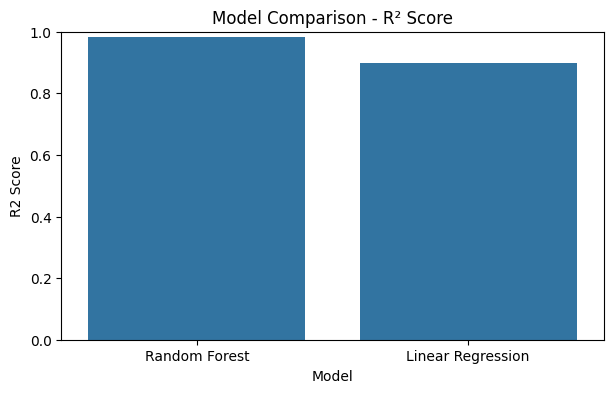

In [27]:
# Compare R² scores
plt.figure(figsize=(7, 4))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison - R² Score")
plt.ylim(0, 1)
plt.show()

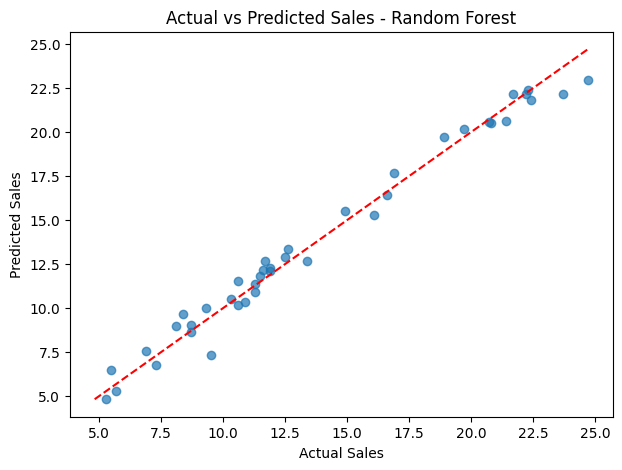

In [28]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.7
)

# Ideal prediction line
min_value = min(y_test.min(), rf_predictions.min())
max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Random Forest")
plt.show()

In [29]:
# Select the best model using test R²
if rf_results["R2 Score"] > lr_results["R2 Score"]:
    best_model = rf_model
    best_predictions = rf_predictions
    best_name = "Random Forest"
else:
    best_model = lr_model
    best_predictions = lr_predictions
    best_name = "Linear Regression"

print("Best model:", best_name)

Best model: Random Forest


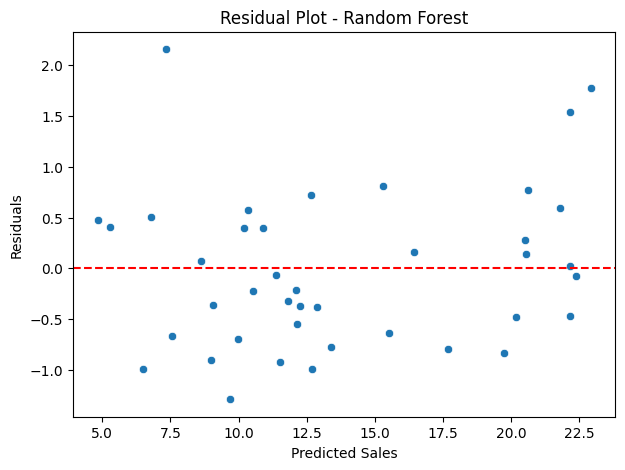

In [30]:
# Calculate residuals
residuals = y_test - best_predictions

plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=best_predictions,
    y=residuals
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title(f"Residual Plot - {best_name}")
plt.show()

In [31]:
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

               Feature  Importance
0         TV_Ad_Budget    0.624810
1      Radio_Ad_Budget    0.362201
2  Newspaper_Ad_Budget    0.012989


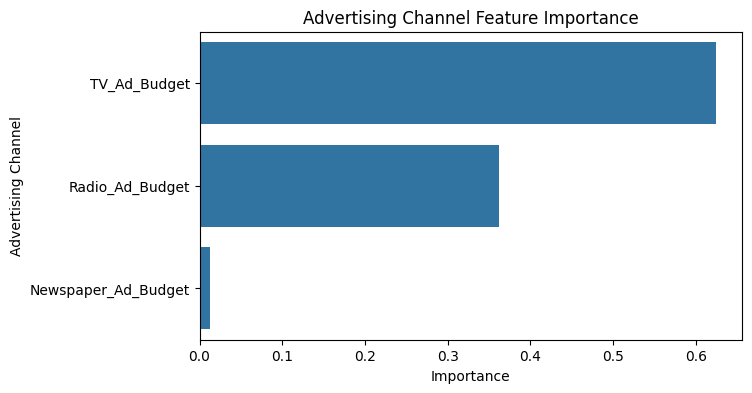

In [32]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Advertising Channel Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Advertising Channel")
plt.show()

In [33]:
top_channel = importance_df.iloc[0]["Feature"]

print("Highest-ranked advertising channel:", top_channel)

Highest-ranked advertising channel: TV_Ad_Budget


In [35]:
# New advertising budget
new_data = pd.DataFrame({
    "TV_Ad_Budget": [200],
    "Radio_Ad_Budget": [30],
    "Newspaper_Ad_Budget": [40]
})

# Predict sales using the best model
predicted_sales = best_model.predict(new_data)

print("Predicted Sales:", round(predicted_sales[0], 2))

Predicted Sales: 18.31


### **Conclusion**

- **Random Forest Regressor outperformed Linear Regression** across all three evaluation metrics, demonstrating better predictive performance for advertising sales prediction.
- Random Forest achieved an **R² score of 0.9813**, explaining approximately **98.13% of the variance** in sales, compared with 89.94% for Linear Regression.
- It also recorded lower prediction errors, with an **MAE of 0.6201** and an **RMSE of 0.7686**, compared with Linear Regression's MAE of 1.4608 and RMSE of 1.7816.
- **Overall, Random Forest is the best-performing model** for this dataset, providing more accurate sales predictions. The model's feature importance can further help identify which advertising channel contributes most to its predictions.